# English writing manuals: what we hold, and a first look at point of view

*For the team discussion on 13 November 2026. Question: what can we write in the application for the conference in May?*

This notebook is a reading text. The figures use the cleaned English books. The steps that decided which file goes in which folder are in `src/fulltext/` and `docs/research_log.md`.


In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Markdown, display
from src.analysis import corpus_stats as cs, plots

plots.set_style()
pd.set_option("display.max_colwidth", 120)
stats = cs.load_book_stats()
books = stats[stats["in_analysis_set"]].copy()
time_books = cs.load_time_books(stats)
meta = cs.load_meta()
say = lambda text: display(Markdown(text))

files = stats["corpus_role"].value_counts()
assert (int(files.get("primary", 0)), int(files.get("comparison", 0))) == (446, 41)
assert len(books) == 432
say(f"**Data snapshot:** table built {meta['built']} from commit `{meta['git_commit']}`"
    f"{' plus uncommitted changes' if meta['uncommitted_changes_at_build'] else ''}; "
    f"POV word list v{meta['lexicon_version']}.")


**Data snapshot:** table built 2026-11-12 20:42 from commit `a8a4f9a` plus uncommitted changes; POV word list v0.1.

## 1. Where the books come from

Two lists were the starting point. They are catalogues, not the books themselves.

- **A seed bibliography** of 50 English titles we agreed are clearly relevant (`data/raw/seed_corpus/`). It is the benchmark: if the pipeline is working, these titles should end up in `primary`.
- **A colleague's download from Open Library**, searched on the subject "creative writing" (`data/raw/colleague_openlibrary/`). It is large and noisy. A cleaned subset lives in `data/interim/filtered_openlibrary/`.

[src/candidates/build_final_lists.py](../src/candidates/build_final_lists.py) merges those lists (and a few smaller ones) into `data/interim/final_lists/`. We then tried to obtain a file for each title. The files we hold are under `data/raw/books/en/`. A fuller account is in [docs/candidate_lists.md](../docs/candidate_lists.md).

**Metadata we can use in the analysis**

| Field | What it is | Limit |
|---|---|---|
| Title, author | The name we show, after a check against the file | Some files turned out to be a different book |
| Edition year | Year of the copy we hold | Often the same catalogue record as the first-publication year |
| First-publication year | Used only when it comes from the seed list or from Open Library joined by work id, and only with no doubt about the book's identity | Missing for many books; those books are left out of the time figure |
| Folder | `primary` or `comparison` | Most `primary` labels are still an automatic proposal |
| Robustness group | Fiction manuals, or pedagogy / genre craft, inside `primary` | A check, not a second corpus |
| Format, word count | PDF or e-book; length of the extracted text | |
| POV term counts | How often precise POV words occur, per book and per 10,000 words | A word count, not a judgement that the book teaches point of view |

What we do **not** have for most books: a hand-checked type (the protocol's types A–F), and a year of first publication that is independent of the catalogue record.


## 2. What kind of books are in the two folders?

**Primary** means: the subject of the book is narrative or creative writing. That includes fiction-writing manuals, school creative-writing teaching and exercises, screen / poetry / drama craft, creative nonfiction, and therapy writing that teaches people to write narrative. **Comparison** is a small contrast group only: narratology, and academic writing about writing. Journalism and songwriting are in neither folder.

Inside primary we keep a split, so we can see whether school books and genre craft behave like fiction manuals. They stay in primary either way.


In [2]:
left_out = int((~stats["in_analysis_set"]).sum())
per_folder, elsewhere = cs.seed_placement()
manuals = "\n".join(f"- {title}" for title in cs.example_titles(books, "fiction_manual"))
craft = "\n".join(f"- {title}" for title in cs.example_titles(books, "pedagogy_genre_craft"))
n_manual = int((books.primary_group == "fiction_manual").sum())
n_craft = int((books.primary_group == "pedagogy_genre_craft").sum())
n_contrast = int((books.primary_group == "contrast").sum())
say(f"**In the figures:** {len(books)} books "
    f"({n_manual} fiction manuals, {n_craft} pedagogy or genre craft, {n_contrast} comparison). "
    f"{left_out} files were left out because the scan needs OCR, the text is under 10,000 words, "
    f"or the file is a second copy of a work already counted.\n\n"
    f"**Seeds.** {per_folder.sum()} English seed titles have a file; {per_folder.get('primary', 0)} are in `primary`. "
    f"The other {len(elsewhere)} files are different books that were matched to a seed record by mistake, "
    f"so we do not hold those two titles.\n\n"
    f"**Fiction-writing manuals** (examples):\n\n{manuals}\n\n"
    f"**Pedagogy and genre craft, still inside primary** (examples):\n\n{craft}")
display(cs.comparison_by_reason(books))
say("**How to read the table.** Each row is one kind of comparison book. "
    "The examples are real titles from the folder, not a complete list.")


**In the figures:** 432 books (279 fiction manuals, 121 pedagogy or genre craft, 32 comparison). 55 files were left out because the scan needs OCR, the text is under 10,000 words, or the file is a second copy of a work already counted.

**Seeds.** 45 English seed titles have a file; 43 are in `primary`. The other 2 files are different books that were matched to a seed record by mistake, so we do not hold those two titles.

**Fiction-writing manuals** (examples):

- 1001 brilliant writing ideas — Ron Shaw
- English as a creative art: literary concepts linked to creative writing — Linden Peach
- New ideas in the writing arts — Graeme Harper
- The Craft of Research — Wayne C. Booth
- The practical writer with Readings — Edward P. Bailey
- he Writer’s Harbrace Handbook Essays- Cheryl Glenn — 

**Pedagogy and genre craft, still inside primary** (examples):

- 300 creative writing activities for the composition class — Edwin P Grobe
- Creative writing — Kathleen C. Phillips
- How to write an autobiographical novel — Alexander Chee
- Rewrite Your Life — Jessica Lourey
- The art of writing — F. M. Salter
- You can write poetry — Jeff Mock

,Kind of book,Books,Examples
0,Academic / composition writing,17,A short guide to writing about film — Timothy Corrigan; What writing does and how it does it An Introduction to Anal...
1,Research on creative writing,7,Becoming a writing researcher — Ann M. Blakeslee; The writer in the academy — Richard Marggraf Turley
2,Scholarship on literature / writing,4,Creative Writing and the New Humanities — Paul Dawson; Therapeutic dimensions of autobiography in creative writing —...
3,Narratology / narrative theory,4,Metafiction: the theory and practice of self-conscious fiction — Patricia Waugh; Towards a poetics of creative writi...


**How to read the table.** Each row is one kind of comparison book. The examples are real titles from the folder, not a complete list.

## 3. How to read the numbers

- **Median.** The typical book: half the books are lower, half are higher. One very long or very dense book does not pull it.
- **Middle half.** Where the central half of the books sit. If it is wide, books in the same folder differ a lot from each other.
- **Per 10,000 words.** The count divided by the length of the book, so a short handbook and a long one can be compared. One term per 10,000 words is rare. Five means the book keeps returning to the topic.
- **The line through a percentage, or the shaded band.** The range that still fits, given that we only have this many books. It says nothing about a wrong label or an untested word list.
- **A log scale.** Each step to the right (or up) is ten times more. It keeps a book with almost no POV words and a book full of them on the same figure. A book with no POV term at all sits at 0.

The numbers below are for **fiction-writing manuals against the comparison group**. That is the cleaner contrast. Pedagogy and genre craft are shown beside them, not mixed into the manual median.


In [3]:
fm = books[books.primary_group == "fiction_manual"]
pg = books[books.primary_group == "pedagogy_genre_craft"]
ct = books[books.primary_group == "contrast"]
say(f"**Fiction manuals** (n = {len(fm)}): median {fm.pov_per_10k.median():.1f} POV terms per 10,000 words "
    f"(middle half {fm.pov_per_10k.quantile(0.25):.1f}–{fm.pov_per_10k.quantile(0.75):.1f}). "
    f"{(fm.pov_per_10k >= 5).mean():.0%} of them reach 5 or more.\n\n"
    f"**Comparison** (n = {len(ct)}): median {ct.pov_per_10k.median():.1f} "
    f"(middle half {ct.pov_per_10k.quantile(0.25):.1f}–{ct.pov_per_10k.quantile(0.75):.1f}). "
    f"{(ct.pov_per_10k >= 5).mean():.0%} reach 5 or more.\n\n"
    f"**Pedagogy and genre craft** (n = {len(pg)}), still inside primary: median {pg.pov_per_10k.median():.1f}. "
    f"They sit with the comparison group, not with the fiction manuals. "
    f"If we had reported one number for all of primary, the manuals would have looked less distinctive than they are.")


**Fiction manuals** (n = 279): median 5.3 POV terms per 10,000 words (middle half 1.7–13.0). 51% of them reach 5 or more.

**Comparison** (n = 32): median 2.0 (middle half 1.4–4.5). 25% reach 5 or more.

**Pedagogy and genre craft** (n = 121), still inside primary: median 2.1. They sit with the comparison group, not with the fiction manuals. If we had reported one number for all of primary, the manuals would have looked less distinctive than they are.

## 4. How often the words occur

Each dot is one book. The black bar is the middle half. The black tick is the median.


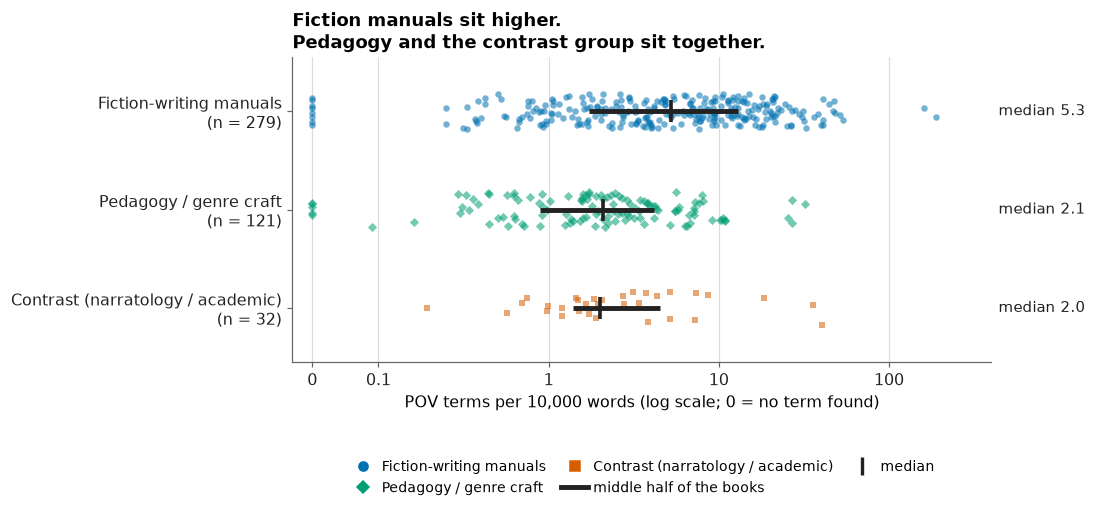

In [4]:
fig = plots.plot_pov_density_robustness(books)
plots.save_figure(fig, "fig4b_pov_density_robustness")


There is no agreed cut-off for "this book discusses point of view substantially". The curve shows every cut-off. The dotted lines are only examples: 1 per 10,000 words, and 5.


At 1 or more per 10,000 words: Fiction-writing manuals 84% (n = 279); Contrast (narratology / academic) 81% (n = 32).

At 5 or more per 10,000 words: Fiction-writing manuals 51% (n = 279); Contrast (narratology / academic) 25% (n = 32).

Pedagogy and genre craft, for comparison: 71% reach 1 or more, 22% reach 5 or more (n = 121). That is close to the comparison group, not to the fiction manuals.

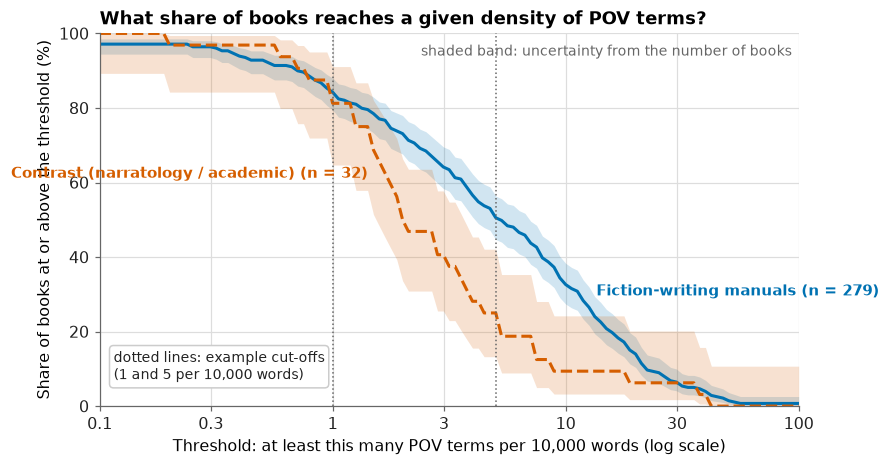

In [5]:
clean = books[books.primary_group.isin(["fiction_manual", "contrast"])]
fig = plots.plot_threshold_curve(
    clean, role_column="primary_group",
    roles=["fiction_manual", "contrast"],
    role_labels=cs.PRIMARY_GROUP_LABELS,
)
plots.save_figure(fig, "fig5_threshold_curve")
for thr in (1, 5):
    bits = []
    for key in ("fiction_manual", "contrast"):
        part = books[books.primary_group == key]
        bits.append(f"{cs.PRIMARY_GROUP_LABELS[key]} {(part.pov_per_10k >= thr).mean():.0%} (n = {len(part)})")
    say(f"At {thr} or more per 10,000 words: " + "; ".join(bits) + ".")
say("Pedagogy and genre craft, for comparison: "
    f"{(pg.pov_per_10k >= 1).mean():.0%} reach 1 or more, {(pg.pov_per_10k >= 5).mean():.0%} reach 5 or more "
    f"(n = {len(pg)}). That is close to the comparison group, not to the fiction manuals.")


### Which aspects of point of view appear?

Each mark is the share of books that use that aspect at least once. The line through the mark is the uncertainty that comes from having only this many books. Fiction manuals are blue, the contrast group is orange. Where the two lines do not overlap, the difference is unlikely to be chance alone. It still does not correct a wrong label or an untested word.


**What we see.** The words for point of view in general, and the words for grammatical person, are common in both groups. The more technical aspects (a character's mind, thought representation, reliability, distance) are found in a smaller share of books, and more often in the fiction manuals.

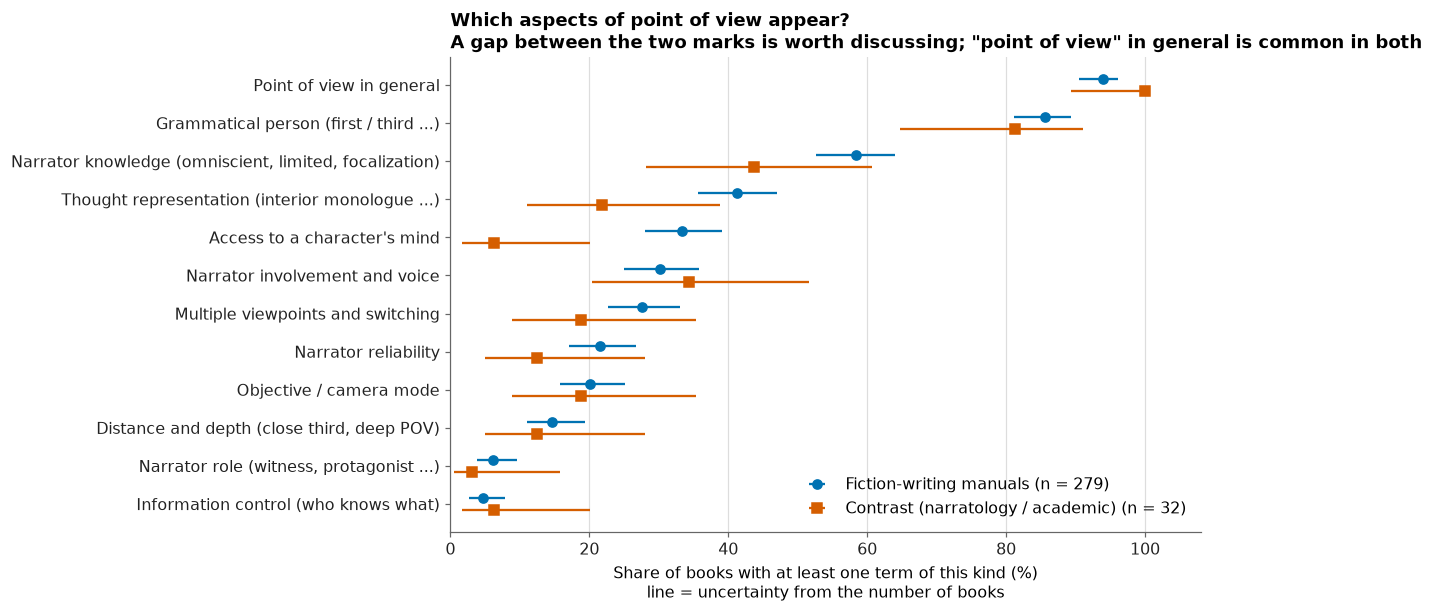

In [6]:
fig = plots.plot_dimension_shares(
    clean, role_column="primary_group",
    roles=["fiction_manual", "contrast"],
    role_labels=cs.PRIMARY_GROUP_LABELS,
)
plots.save_figure(fig, "fig6_dimension_shares")
say("**What we see.** The words for point of view in general, and the words for grammatical person, "
    "are common in both groups. The more technical aspects (a character's mind, thought representation, "
    "reliability, distance) are found in a smaller share of books, and more often in the fiction manuals.")


### By decade of first publication

Only books with a clean year of first publication are drawn. Books with no such year are left out, and the title says how many. Comparison is too small to split by decade, so the figure shows fiction manuals only. For most dated books the first-publication year is the same catalogue record as the edition year, so this is not yet a history of the genre.


**What we see.** 168 of 279 fiction manuals have a clean first-publication year; the other 111 are not in the figure. Where a decade is drawn, it has at least 20 of those dated books. The middle halves overlap: the differences between decades are small next to the differences between books.

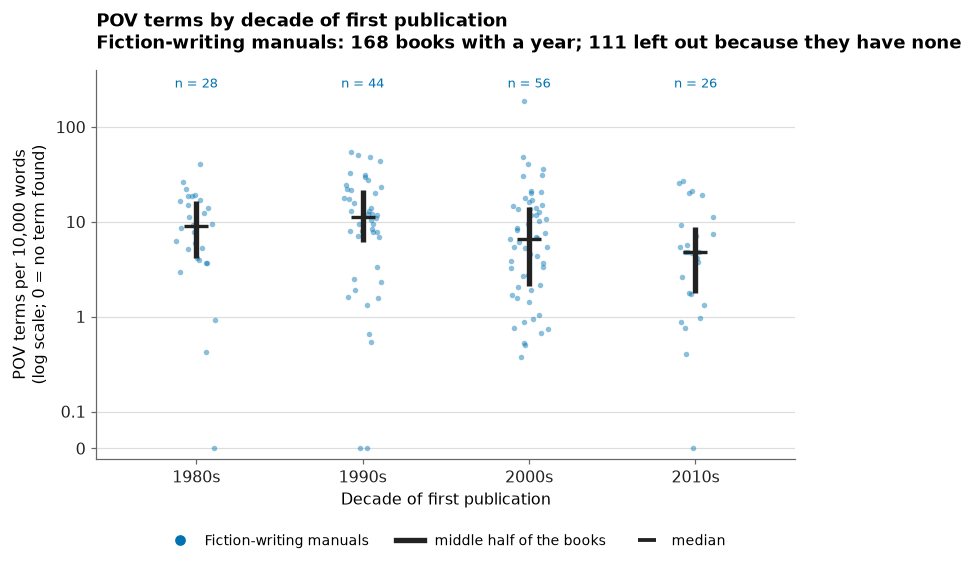

In [7]:
manuals_time = time_books[time_books.primary_group == "fiction_manual"]
assert manuals_time.loc[manuals_time.work_year_clean.notna(), "work_year_clean"].notna().all()
fig = plots.plot_density_by_decade(
    manuals_time, group_column="primary_group", groups=["fiction_manual"],
    group_labels=cs.PRIMARY_GROUP_LABELS,
)
plots.save_figure(fig, "fig7_density_by_decade")
dated = int(manuals_time.work_year_clean.notna().sum())
say(f"**What we see.** {dated} of {len(manuals_time)} fiction manuals have a clean first-publication year; "
    f"the other {len(manuals_time) - dated} are not in the figure. "
    f"Where a decade is drawn, it has at least 20 of those dated books. "
    f"The middle halves overlap: the differences between decades are small next to the differences between books.")


## 5. The point-of-view word list

The list is [config/pov_lexicon.yml](../config/pov_lexicon.yml), version 0.1. It sorts POV vocabulary into twelve aspects. Each aspect has precise terms (`high`), looser terms (`medium`) and words that are never enough on their own (`context`, such as "voice" or "distance").

**What we counted.** Only the precise English terms, plus a few patterns that catch plurals and hyphens, in the body of the book. We did not count the loose words. A match is a word, not a passage that *teaches* point of view. "Point of view" can also mean "opinion".

The table is for fiction manuals. The share is the percentage of those books that use the aspect at least once.


In [8]:
display(cs.lexicon_table(books))


,Aspect,Example terms,Fiction manuals with at least one,In plain words
0,Point of view in general,"point of view, POV",94%,"The topic named as such: point of view, viewpoint."
1,Grammatical person (first / third ...),"first-person narrator, first-person point of view",86%,"Whether the story is told as I, you, or he/she."
2,"Narrator knowledge (omniscient, limited, focalization)","omniscient narrator, omniscient point of view",58%,"How much the narrator knows: omniscient, limited, focalization."
3,Thought representation (interior monologue ...),"free indirect discourse, free indirect style",41%,"How a character's thoughts are written (interior monologue, free indirect style)."
4,Access to a character's mind,"access to consciousness, interior access",33%,Whether the text can enter a character's mind.
5,Narrator involvement and voice,"detached narrator, involved narrator",30%,"Whether the narrator steps in, and what the voice sounds like."
6,Multiple viewpoints and switching,"multiple POV, multiple viewpoints",28%,"More than one viewpoint, and changing between them."
7,Narrator reliability,"unreliable narrator, unreliable narration",22%,Whether the narrator can be trusted.
8,Objective / camera mode,"camera eye, fly on the wall",20%,Telling only what a camera could see.
9,"Distance and depth (close third, deep POV)","deep POV, deep third",15%,"How close the telling stays to a character (close third, deep POV)."


**What this is good for, and what it is not.**

- It describes which parts of the vocabulary are common (person, the words "point of view") and which are specialist (reliability, distance, the camera eye). That is already a result: a prevalence claim cannot treat "mentions POV" as "discusses POV".
- The same terms can later mark *passages* for close reading: a page that contains "unreliable narrator" is a better place to start than a random page.
- Google Books ngrams, which we already use for phrases such as "creative writing" ([config/ngram_terms.yml](../config/ngram_terms.yml)), could show when words like "free indirect discourse" entered published English. That is a history of the public language, not of these manuals.
- Topic models or a classifier would need a human-labelled sample of passages first. The list is a way to find candidate passages. It is not a model.

**A rough check of the matches** (one reading, before the folders were re-sorted; not a measurement): in an earlier primary sample, 2 of 20 matches were not about narrative point of view; in comparison, 9 of 20. Typical misses: "point of view" meaning "opinion", "second person" in a grammar lesson, "POV" as a camera direction.


## 6. What we can say tomorrow

**Supportable**

- We can describe how the candidate lists were built and which files we hold.
- We hold a machine-readable English set of narrative-writing books, with fiction manuals separated from pedagogy and genre craft, and a small narratology / academic contrast group.
- In that cleaner contrast, fiction manuals use POV vocabulary more densely than the contrast group (median about 5 per 10,000 words against about 2). Pedagogy and genre craft look like the contrast group, not like the manuals.
- "Mentions point of view" is a weak measure: the general words are common in both groups. The specialist aspects are not.

**Not yet**

- A percentage of "writing manuals" in the world that discuss POV. These are the books we could obtain, and most labels are still unchecked.
- Change over time. Many books have no clean first-publication year, and the year we do have is often the same record as the edition.
- A tested definition of "substantial" discussion, or a statistical claim that would survive a hand-check of the labels.

**Questions for the meeting**

1. Do we apply now with a corpus-and-methods paper, or wait until a sample of passages has been read by hand?
2. For the main claim, do we report fiction manuals, or the broader primary that includes school books and screen, poetry and drama?
3. Is a contrast group of about 30 narratology and academic books the comparison we want?

```bash
python -m src.analysis.corpus_stats
python -m src.publication.build_en_biblio_timeline
jupyter nbconvert --to notebook --execute --inplace notebooks/04_corpus_descriptive_stats_en.ipynb
jupyter nbconvert --to html --no-input --output-dir notebooks/exports notebooks/04_corpus_descriptive_stats_en.ipynb
```

This primary is broader than section 2 of [docs/scientific_readme.md](../docs/scientific_readme.md), where school books and screen, poetry and drama were comparison. The research log records the change.
